# 01 — Exploratory Data Analysis

**Purpose:** Understand the raw BTC/USDT 5-minute dataset before feature engineering.

Sections:
1. Data loading and schema inspection
2. Price distribution and stationarity tests
3. Return distribution (fat tails, skew)
4. Volume patterns by hour/day
5. Label distribution (up/down class balance)
6. Missing data audit
7. Correlation heatmap (raw OHLCV fields)
8. Regime detection (volatility clustering)


In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='darkgrid', palette='husl')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11
print('Libraries loaded.')

Libraries loaded.


## 1. Data Loading

In [2]:
# Load from extracted CSV
df = pd.read_csv('../data/bitcoin_180d.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'], unit='ms')
df['label'] = (df['close'].shift(-5) > df['close']).astype('Int64')
df.set_index('timestamp', inplace=True)

print(f'Dataset: {len(df):,} rows, {df.index.min()} → {df.index.max()}')
print(f'Missing: {df.isnull().sum().sum()}')
df.head()


Dataset: 51,840 rows, 2025-11-19 21:15:00 → 2026-05-18 21:10:00
Missing: 0


,open,high,low,close,volume,taker_buy,trade_count,label
timestamp,,,,,,,,
2025-11-19 21:15:00,89694.17,89935.54,89685.50,89912.65,65.20751,35.32769,20186.0,1
2025-11-19 21:20:00,89912.65,90850.00,89912.65,90454.24,573.55756,333.67588,74047.0,0
2025-11-19 21:25:00,90454.24,90509.31,90020.00,90118.00,226.18019,107.94485,38397.0,1
2025-11-19 21:30:00,90118.00,90491.03,90063.09,90488.28,261.05325,189.59660,34096.0,1
2025-11-19 21:35:00,90488.27,90636.17,90376.00,90376.01,277.63606,116.62630,30731.0,1


## 2. Price Distribution & Stationarity

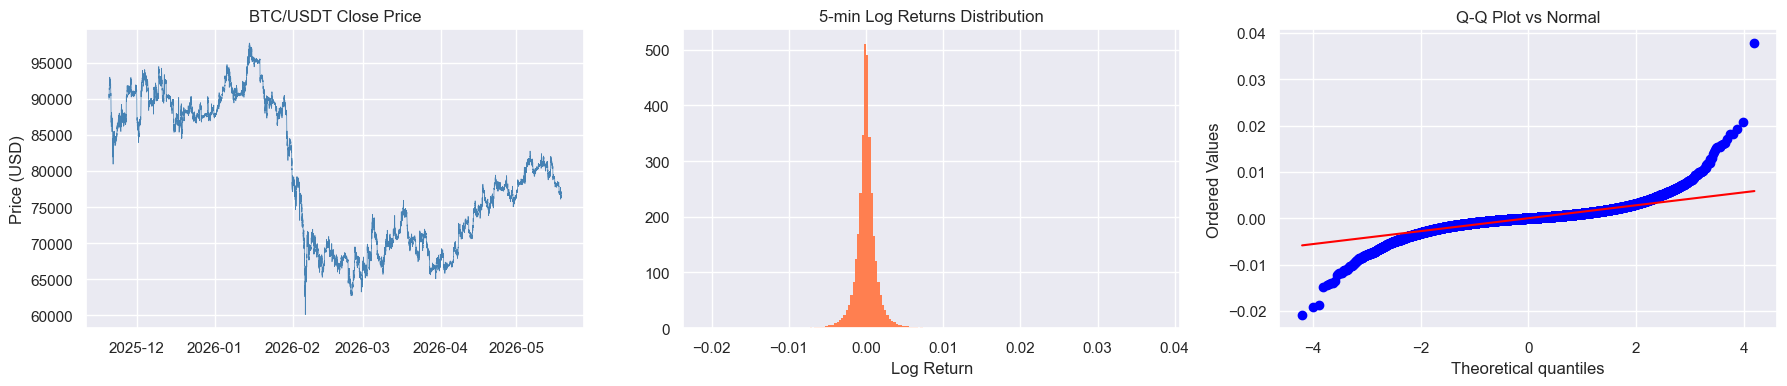

Skewness: 0.4415
Kurtosis (excess): 21.6240


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Price series
axes[0].plot(df.index, df['close'], linewidth=0.5, color='steelblue')
axes[0].set_title('BTC/USDT Close Price')
axes[0].set_ylabel('Price (USD)')

# Log returns distribution
log_ret = np.log(df['close'] / df['close'].shift(1)).dropna()
axes[1].hist(log_ret, bins=200, color='coral', edgecolor='none', density=True)
axes[1].set_title('5-min Log Returns Distribution')
axes[1].set_xlabel('Log Return')

# QQ plot
stats.probplot(log_ret.dropna(), dist='norm', plot=axes[2])
axes[2].set_title('Q-Q Plot vs Normal')

plt.tight_layout()
plt.savefig('01_price_distribution.png', dpi=120)
plt.show()

print(f'Skewness: {log_ret.skew():.4f}')
print(f'Kurtosis (excess): {log_ret.kurtosis():.4f}')

## 3. Label Distribution

UP (1):   26,039  (50.2%)
DOWN (0): 25,801  (49.8%)


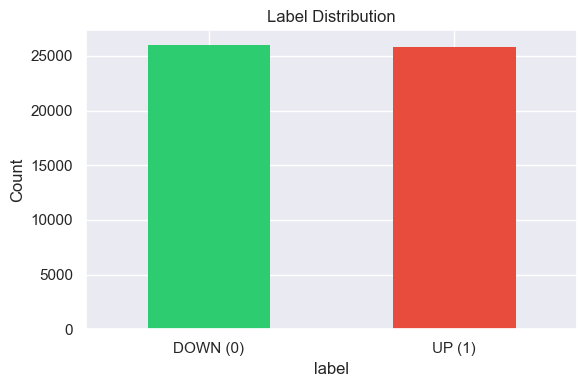

In [4]:
labeled = df['label'].dropna()
counts = labeled.value_counts()
print(f"UP (1):   {counts.get(1, 0):,}  ({counts.get(1, 0)/len(labeled)*100:.1f}%)")
print(f"DOWN (0): {counts.get(0, 0):,}  ({counts.get(0, 0)/len(labeled)*100:.1f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
counts.plot(kind='bar', ax=ax, color=['#2ecc71', '#e74c3c'], edgecolor='none')
ax.set_xticklabels(['DOWN (0)', 'UP (1)'], rotation=0)
ax.set_title('Label Distribution')
ax.set_ylabel('Count')
plt.tight_layout()
plt.savefig('01_label_distribution.png', dpi=120)
plt.show()

## 4. Volume Patterns by Hour

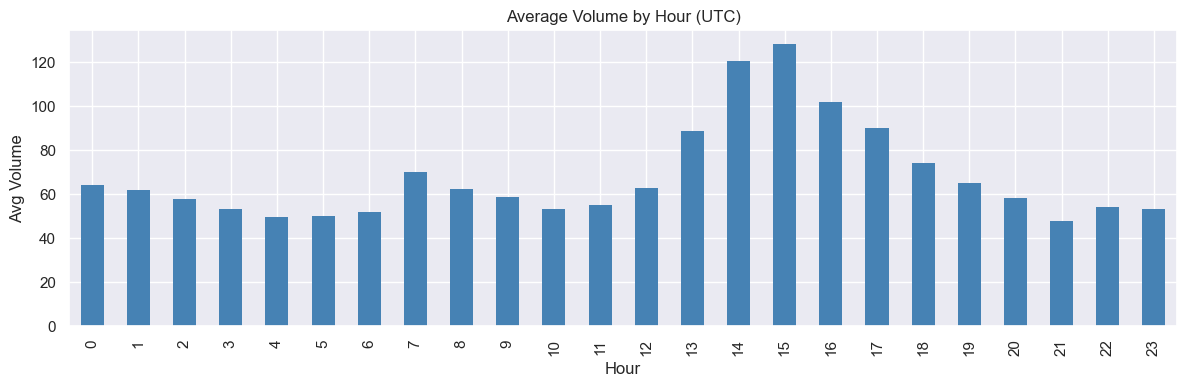

In [5]:
df['hour'] = df.index.hour
vol_by_hour = df.groupby('hour')['volume'].mean()

fig, ax = plt.subplots(figsize=(12, 4))
vol_by_hour.plot(kind='bar', ax=ax, color='steelblue', edgecolor='none')
ax.set_title('Average Volume by Hour (UTC)')
ax.set_xlabel('Hour')
ax.set_ylabel('Avg Volume')
plt.tight_layout()
plt.savefig('01_volume_by_hour.png', dpi=120)
plt.show()

## 5. Volatility Regime Detection

In [6]:
df['realized_vol'] = log_ret.rolling(12).std() * np.sqrt(12 * 24 * 365)  # annualized

# Classify regimes
vol_33 = df['realized_vol'].quantile(0.33)
vol_67 = df['realized_vol'].quantile(0.67)

def classify_regime(v):
    if pd.isna(v): return 'Unknown'
    if v < vol_33: return 'Low Vol'
    if v < vol_67: return 'Mid Vol'
    return 'High Vol'

df['regime'] = df['realized_vol'].apply(classify_regime)
print('Regime distribution:')
print(df['regime'].value_counts())

# Win rate by regime
labeled_df = df.dropna(subset=['label'])
print('\nLabel=1 rate by regime:')
print(labeled_df.groupby('regime')['label'].mean())

Regime distribution:
regime
Mid Vol     17622
High Vol    17103
Low Vol     17103
Unknown        12
Name: count, dtype: int64

Label=1 rate by regime:
regime
High Vol    0.513185
Low Vol     0.497574
Mid Vol     0.496255
Unknown     0.583333
Name: label, dtype: Float64


## 6. Missing Data Audit

In [7]:
# Check for gaps in 5-minute timeline
time_diffs = df.index.to_series().diff().dropna()
gaps = time_diffs[time_diffs > pd.Timedelta('5min')]
print(f'Timeline gaps (>5min): {len(gaps)}')
if len(gaps) > 0:
    print(gaps.sort_values(ascending=False).head(10))

Timeline gaps (>5min): 0
